# Phase D: Exploratory Data Analysis (EDA)
## Customer Retention & Revenue Intelligence Platform
### Business Context & Analytical Objectives:
1. **Executive Performance:** Total GMV, net revenue, order volume, Average Order Value (AOV).
2. **Monthly Growth Velocity:** MoM order velocity and revenue trajectory.
3. **Category Performance:** Pareto 80/20 sales concentration and top grossing product lines.
4. **Logistics & Satisfaction:** Delivery SLAs, fulfillment delay distributions, and customer rating impacts.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

DATA_DIR = '../data/processed'
orders = pd.read_csv(os.path.join(DATA_DIR, 'orders_enriched.csv'))
categories = pd.read_csv(os.path.join(DATA_DIR, 'category_performance.csv'))
print(f"Loaded orders_enriched: {orders.shape[0]:,} records")
print(f"Loaded category_performance: {categories.shape[0]:,} categories")


Matplotlib is building the font cache; this may take a moment.


Loaded orders_enriched: 99,441 records
Loaded category_performance: 74 categories


### 1. Executive Revenue & Order KPIs

In [2]:
total_orders = orders['order_id'].nunique()
total_customers = orders['customer_unique_id'].nunique()
total_revenue = orders['total_order_value'].sum()
aov = total_revenue / total_orders
avg_review = orders['review_score'].mean()

print(f"--- Executive Summary ---")
print(f"Total Orders:            {total_orders:,}")
print(f"Total Unique Customers:  {total_customers:,}")
print(f"Total Revenue:           R$ {total_revenue:,.2f}")
print(f"Average Order Value:     R$ {aov:,.2f}")
print(f"Average Review Score:    {avg_review:.2f} / 5.0")


--- Executive Summary ---
Total Orders:            99,441
Total Unique Customers:  96,096
Total Revenue:           R$ 15,843,553.24
Average Order Value:     R$ 159.33
Average Review Score:    4.09 / 5.0


### 2. Monthly Revenue Trajectory & Order Volume

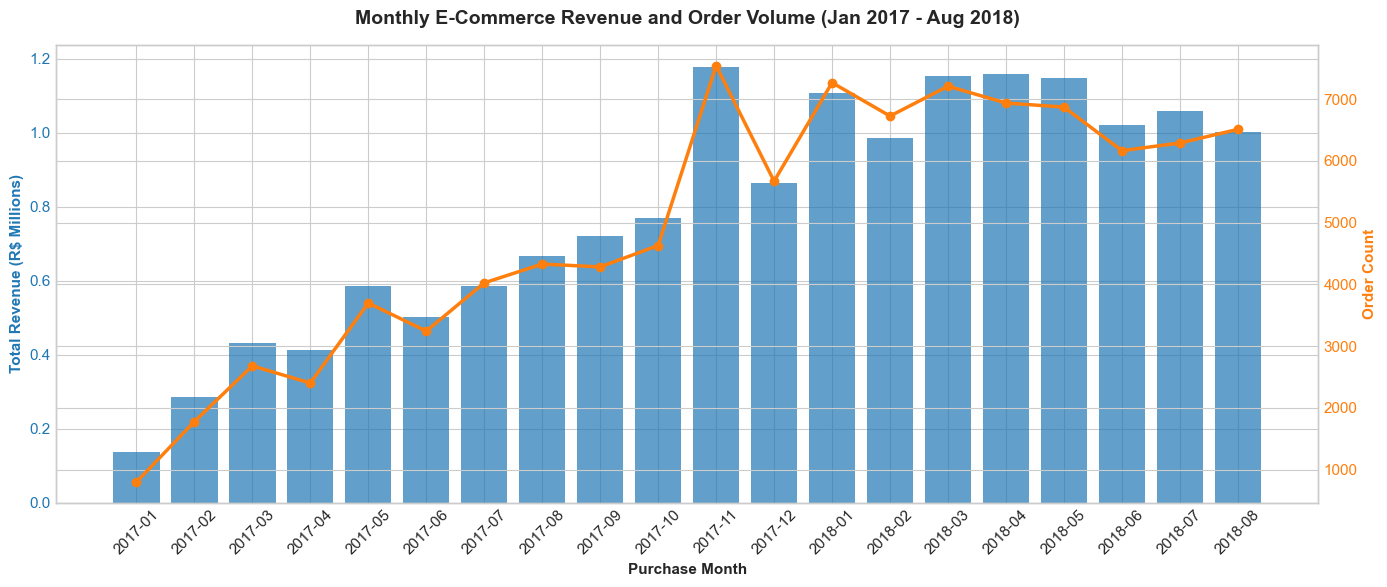

In [3]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['year_month'] = orders['order_purchase_timestamp'].dt.to_period('M').astype(str)

# Filter complete operating months (exclude 2016 launch & late 2018 cutoff)
monthly = orders[orders['year_month'].between('2017-01', '2018-08')].groupby('year_month').agg(
    monthly_rev=('total_order_value', 'sum'),
    order_count=('order_id', 'nunique')
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))

color = '#1f77b4'
ax1.set_xlabel('Purchase Month', fontweight='bold')
ax1.set_ylabel('Total Revenue (R$ Millions)', color=color, fontweight='bold')
bars = ax1.bar(monthly['year_month'], monthly['monthly_rev'] / 1e6, color=color, alpha=0.7, label='Revenue (M R$)')
ax1.tick_params(axis='y', labelcolor=color)
plt.xticks(rotation=45)

ax2 = ax1.twinx()
color = '#ff7f0e'
ax2.set_ylabel('Order Count', color=color, fontweight='bold')
ax2.plot(monthly['year_month'], monthly['order_count'], color=color, linewidth=2.5, marker='o', label='Order Count')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Monthly E-Commerce Revenue and Order Volume (Jan 2017 - Aug 2018)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()


### 3. Top 10 Product Categories by Revenue (Pareto Analysis)

C:\Users\HARSH SHARMA\AppData\Local\Temp\ipykernel_36072\2944045363.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_cat, x='total_category_revenue', y='product_category_name_english', palette='Blues_r')


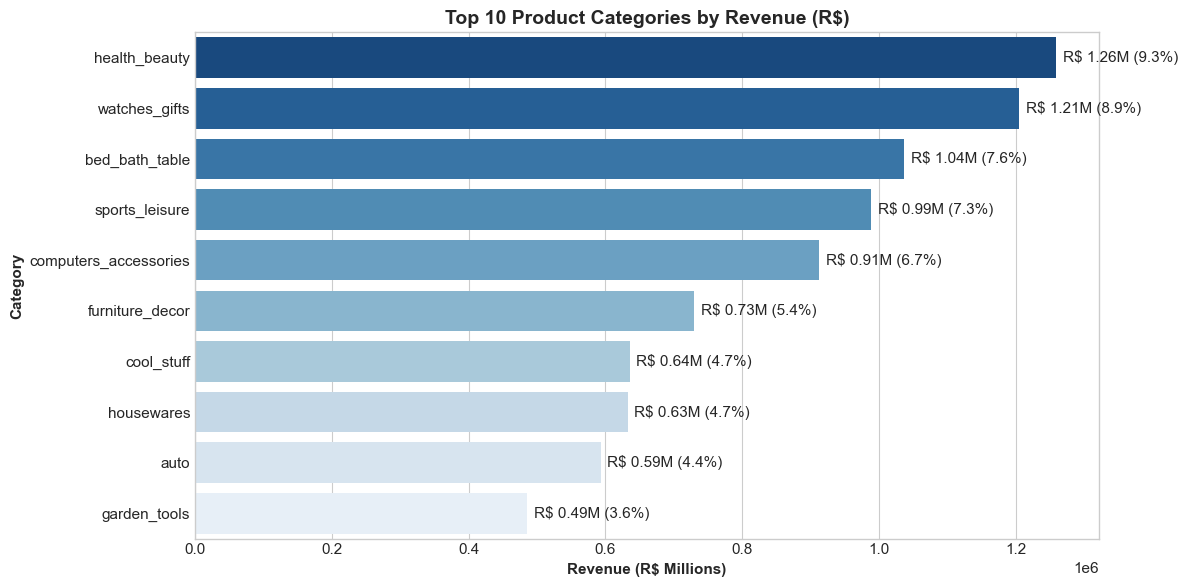

In [4]:
top10_cat = categories.head(10).copy()

plt.figure(figsize=(12, 6))
sns.barplot(data=top10_cat, x='total_category_revenue', y='product_category_name_english', palette='Blues_r')
plt.title('Top 10 Product Categories by Revenue (R$)', fontsize=14, fontweight='bold')
plt.xlabel('Revenue (R$ Millions)', fontweight='bold')
plt.ylabel('Category', fontweight='bold')

for idx, row in enumerate(top10_cat.itertuples()):
    plt.text(row.total_category_revenue + 10000, idx, f"R$ {row.total_category_revenue/1e6:.2f}M ({row.revenue_share_pct:.1f}%)", va='center')

plt.tight_layout()
plt.show()


### 4. Logistics SLA & Delivery Delays vs. Customer Reviews

C:\Users\HARSH SHARMA\AppData\Local\Temp\ipykernel_36072\1689803542.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=delivered, x='review_score', y='actual_delivery_days', palette='viridis', showfliers=False)


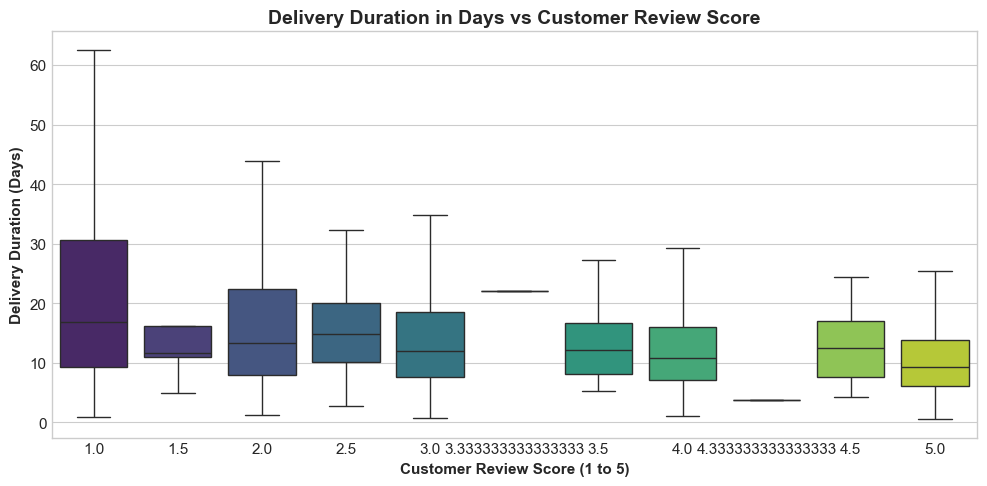

Average Review Score for On-Time Deliveries: 4.29 / 5.0
Average Review Score for Late Deliveries:    2.57 / 5.0
Customer Satisfaction Drop due to Delay:    1.73 rating points (40.2%)


In [5]:
delivered = orders[(orders['order_status'] == 'delivered') & (orders['review_score'].notnull())].copy()

plt.figure(figsize=(10, 5))
sns.boxplot(data=delivered, x='review_score', y='actual_delivery_days', palette='viridis', showfliers=False)
plt.title('Delivery Duration in Days vs Customer Review Score', fontsize=14, fontweight='bold')
plt.xlabel('Customer Review Score (1 to 5)', fontweight='bold')
plt.ylabel('Delivery Duration (Days)', fontweight='bold')
plt.tight_layout()
plt.show()

ontime_avg = delivered[~delivered['is_late_delivery']]['review_score'].mean()
late_avg = delivered[delivered['is_late_delivery']]['review_score'].mean()
print(f"Average Review Score for On-Time Deliveries: {ontime_avg:.2f} / 5.0")
print(f"Average Review Score for Late Deliveries:    {late_avg:.2f} / 5.0")
print(f"Customer Satisfaction Drop due to Delay:    {(ontime_avg - late_avg):.2f} rating points ({((ontime_avg - late_avg)/ontime_avg)*100:.1f}%)")
